<a href="https://colab.research.google.com/github/kavy988/ai-ml-dl-learning/blob/main/deep-learning/06_pytorch_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pytorch Transfer Learning

What is transfer learning?

* Transfer learning allows us to take the patterns (also called weights) another model has learned from another problem and use them for our own problem.

* For example, we can take the patterns a computer vision model has learned from datasets such as ImageNet (millions of images of different objects) and use them to power our FoodVision Mini model.

* Or we could take the patterns from a language model (a model that's been through large amounts of text to learn a representation of language) and use them as the basis of a model to classify different text samples.

* The premise remains: find a well-performing existing model and apply it to your own problem.

Why use transfer learning ?

* There are two main benefits to using transfer learning:

1. Can leverage an existing model (usually a neural network architecture) proven to work on problems similar to our own.

2. Can leverage a working model which has already learned patterns on similar data to our own. This often results in achieving great results with less custom data.

* We'll be putting these to the test for our FoodVision Mini problem, we'll take a computer vision model pretrained on ImageNet and try to leverage its underlying learned representations for classifying images of pizza, steak and sushi.

* Both research and practice support the use of transfer learning too.

* A finding from a recent machine learning research paper recommended practitioners use transfer learning wherever possible.

### TBR -
* we also perform an in-depth analysis of the transfer learning setting for Vision Transformers . we conculde that across a wide range of datasets , even if the downstream data of interest appears to only we weakly related to the data used for pre-training , transfer learning remians the best available option .

* Our analysis also suggests that among similarly performing pre-trained models , for transfer learning a model with more training data should likely be preferred over oen with more data augmentatio .

# 0, Getting setup

lets get started by importing / downloading the required modules for this section.

To savve us writing extra code , we're going to be leaveraging some of the python scripts (such as data_setup.py and engine.py)
we created in the previous section 0.5 going_modular

In [ ]:
import torch
import torchvision

print(torch.__version__)
print(torchvision.__version__)


2.13.0
0.28.0


In [ ]:
import matplotlib.pyplot as plt
from torchvision import transforms
from torch import nn

try :
  from torchinfo import summary

except :
  print("[info] couldn't find torchinfo.... installing it")
  !pip install -q torchinfo
  from torchinfo import summary

try :
  from going_modular.going_modular import data_setup , engine
except :

  # Get the going_modular scripts
  print("[INFO] Couldn't find going_modular scripts... downloading them from GitHub.")
  !git clone https://github.com/mrdbourke/pytorch-deep-learning
  !mv pytorch-deep-learning/going_modular .
  !rm -rf pytorch-deep-learning
  from going_modular.going_modular import data_setup, engine

[INFO] Couldn't find going_modular scripts... downloading them from GitHub.
Cloning into 'pytorch-deep-learning'...
remote: Enumerating objects: 4410, done.
remote: Counting objects: 100% (10/10), done.
remote: Compressing objects: 100% (8/8), done.


In [ ]:
device  = "cuda" if torch.cuda.is_available() else "cpu"
device

## 1. Get data

let's write some code to download the pizza_steak_sushi.zip dataset from the course GitHub and then unzip it.

In [ ]:
import os
import zipfile
from pathlib import Path
import requests

data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

    os.remove(data_path / "pizza_steak_sushi.zip")

In [ ]:
# setup directories/folders. OR the paths to our training directories.

train_dir = image_path / "train"
test_dir = image_path / "test"

# 2. Create datasets and dataloaders

since we've downloaded the going_modular directory , we can use the data_script.py script
we created in section 0.5 Pytorch Going Modular to prepare and setup our DataLoaders.

### 2.1 Creating a transform for torchvision.models (manual creation)


* Note :-
When using a pretrained model, it's important that your custom data going into the model is prepared in the same way as the original training data that went into the model.

In [ ]:
device

In [ ]:
# create a transform pipeline manually (required for torchvision <  0.13 )

manual_transforms = transforms.Compose ([
    transforms.Resize (size = (224, 224)), # 1. Reshape all images to 224x224 (though some models may require different sizes)
    transforms.ToTensor(), # 2. Turn image values to between 0 & 1
    transforms.Normalize(mean = [0.485, 0.456 , 0.406],# 3. A mean of [0.485, 0.456, 0.406] (across each colour channel)
                         std = [0.229, 0.224, 0.225]) # 4. A standard deviation of [0.229, 0.224, 0.225] (across each colour channel),
])


In [ ]:
# create training and testing dataloaders as well as get a list of class names
train_dataloader, test_dataloader , class_names = data_setup.create_dataloaders(train_dir = train_dir ,
                                                                                test_dir = test_dir ,
                                                                                transform = manual_transforms, # resize , convert images to b/w 0 and 1 and normalize them
                                                                                batch_size = 32) # set mini-batch size to 32

train_dataloader, test_dataloader, class_names

### 2.2 Creating a transform for torchvision.models (auto creation)

note :-
As previously stated, when using a pretrained model, it's important that your custom data going into the model is prepared in the same way as the original training data that went into the model.

*  When you setup a model from torchvision.models and select the pretrained model weights you'd like to use, for example, say we'd like to use:

"""weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
Where """,

1. EfficientNet_B0_Weights is the model architecture weights we'd like to use (there are many different model architecture options in torchvision.models).
2. DEFAULT means the best available weights (the best performance in ImageNet).

In [ ]:
# get a set of pretrained model weights
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
weights

In [ ]:
auto_transform = weights.transforms()
auto_transform

Notice how auto_transforms is very similar to manual_transforms, the only difference is that auto_transforms came with the model architecture we chose, where as we had to create manual_transforms by hand.

The benefit of automatically creating a transform through weights.transforms() is that you ensure you're using the same data transformation as the pretrained model used when it was trained.

However, the tradeoff of using automatically created transforms is a lack of customization.

We can use auto_transforms to create DataLoaders with create_dataloaders() just as before.

In [ ]:
train_dataloader , test_dataloader , class_names = data_setup.create_dataloaders(train_dir = train_dir ,
                                                                                test_dir = test_dir,
                                                                                transform = auto_transform,
                                                                                batch_size = 32)
train_dataloader, test_dataloader, class_names

# 3. getting a pretrained model

* The whole idea of transfer learning is to take an already well-performing model on a problem-space similar to yours and then customise it to your use case.



### 3.1 which pre-trained model should you use ?

* it depends =

1. Generally, the higher number in the model name (e.g. efficientnet_b0() -> efficientnet_b1() -> efficientnet_b7()) means better performance but a larger model.

2. You might think better performance is always better, right?
That's true but some better performing models are too big for some devices.

### 3.2 Setting up a pretrained model
The pretrained model we're going to be using is torchvision.models.efficientnet_b0().

The architecture is from the paper EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks.

We can setup the EfficientNet_B0 pretrained ImageNet weights using the same code as we used to create the transforms.

* weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT ,DEFAULT = best available weights for ImageNet

In [ ]:
# OLD: Setup the model with pretrained weights and send it to the target device (this was prior to torchvision v0.13)
# model = torchvision.models.efficientnet_b0(pretrained=True).to(device) # OLD method (with pretrained=True)

# NEW: Setup the model with pretrained weights and send it to the target device (torchvision v0.13+)
import torchvision

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
model = torchvision.models.efficientnet_b0(weights = weights).to(device)

# model # uncomment to output (it's very long)


In [ ]:
model

* Our efficientnet_b0 comes in three main parts:

1. features - A collection of convolutional layers and other various activation layers to learn a base representation of vision data (this base representation/collection of layers is often referred to as features or feature extractor, "the base layers of the model learn the different features of images").

2. avgpool - Takes the average of the output of the features layer(s) and turns it into a feature vector.

3. classifier - Turns the feature vector into a vector with the same dimensionality as the number of required output classes (since efficientnet_b0 is pretrained on ImageNet and because ImageNet has 1000 classes, out_features=1000 is the default).

3.3 Getting a summary of our model with torchinfo.summary()

:- To do so, we'll pass in:

* model - the model we'd like to get a summary of.

* input_size - the shape of the data we'd like to pass to our model, for the case of efficientnet_b0, the input size is (batch_size, 3, 224, 224), though other variants of efficientnet_bX have different input sizes.

* Note: Many modern models can handle input images of varying sizes thanks to torch.nn.AdaptiveAvgPool2d(), this layer adaptively adjusts the output_size of a given input as required. You can try this out by passing different size input images to summary() or your models.

* col_names - the various information columns we'd like to see about our model.

* col_width - how wide the columns should be for the summary.

* row_settings - what features to show in a row.

In [ ]:
# printing a summary using torchinfo

summary(model = model ,
        input_size = (32, 3, 224, 224),
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20,
        row_settings = ["var_names"])

* For reference, our model from previous sections, TinyVGG had 8,083 parameters vs. 5,288,548 parameters for efficientnet_b0, an increase of ~654x!

### 3.4 Freezing the base model and changing the output layer to suit our needs


* The process of transfer learning usually goes: freeze some base layers of a pretrained model (typically the features section) and then adjust the output layers (also called head/classifier layers) to suit your needs.

#### TBR -

* you can customise the outputs of a pretrained model by changing the output layer(s) to suit your problem. The original torchvision.models.efficientnet_b0() comes with out_features=1000 because there are 1000 classes in ImageNet, the dataset it was trained on. However, for our problem, classifying images of pizza, steak and sushi we only need out_features=3.


We can freeze all of the layers/parameters in the features section by setting the attribute requires_grad=False.

For parameters with requires_grad=False, PyTorch doesn't track gradient updates and in turn, these parameters won't be changed by our optimizer during training.

In [ ]:
# freeze all base layers in the 'features' section of the model (the feature extractor )
# by setting requires_grad = False

for param in model.features.parameters():
  param.requires_grad = False



1.  our current classifier consists of :
##### (classifier): Sequential(
    (0): Dropout(p=0.2, inplace=True)
    (1): Linear(in_features=1280, out_features=1000, bias=True))

* We'll keep the Dropout layer the same using torch.nn.Dropout(p=0.2, inplace=True).

* Note :- Dropout layers randomly remove connections between two neural network layers with a probability of p. For example, if p=0.2, 20% of connections between neural network layers will be removed at random each pass. This practice is meant to help regularize (prevent overfitting) a model by making sure the connections that remain learn features to compensate for the removal of the other connections (hopefully these remaining features are more general).

In [ ]:
# set the manual seeds

torch.manual_seed(42)
torch.cuda.manual_seed(42)

# get the lenght of class_names (one output unit for each class)
output_shape = len(class_names)

# recreate the classifier layer and seed it to the target device
model.classifier = torch.nn.Sequential(
    torch.nn.Dropout(p = 0.2 , inplace = True),
    torch.nn.Linear(in_features = 1280,
                    out_features = output_shape,
                    bias = True)).to(device)



Output layer updated, let's get another summary of our model and see what's changed.

In [ ]:
# Do a summary *after* freezing the features and changing the output classifier layer (uncomment for actual output)

summary(model = model ,
        input_size = (32, 3, 224 , 224),# make sure this is "input_size", not "input_shape" (batch_size, color_channels, height, width)
        verbose = 0,
        col_names = ["input_size" , "output_size" , "num_params" , "trainable"],
        col_width = 20,
        row_settings = ["var_names"]
        )


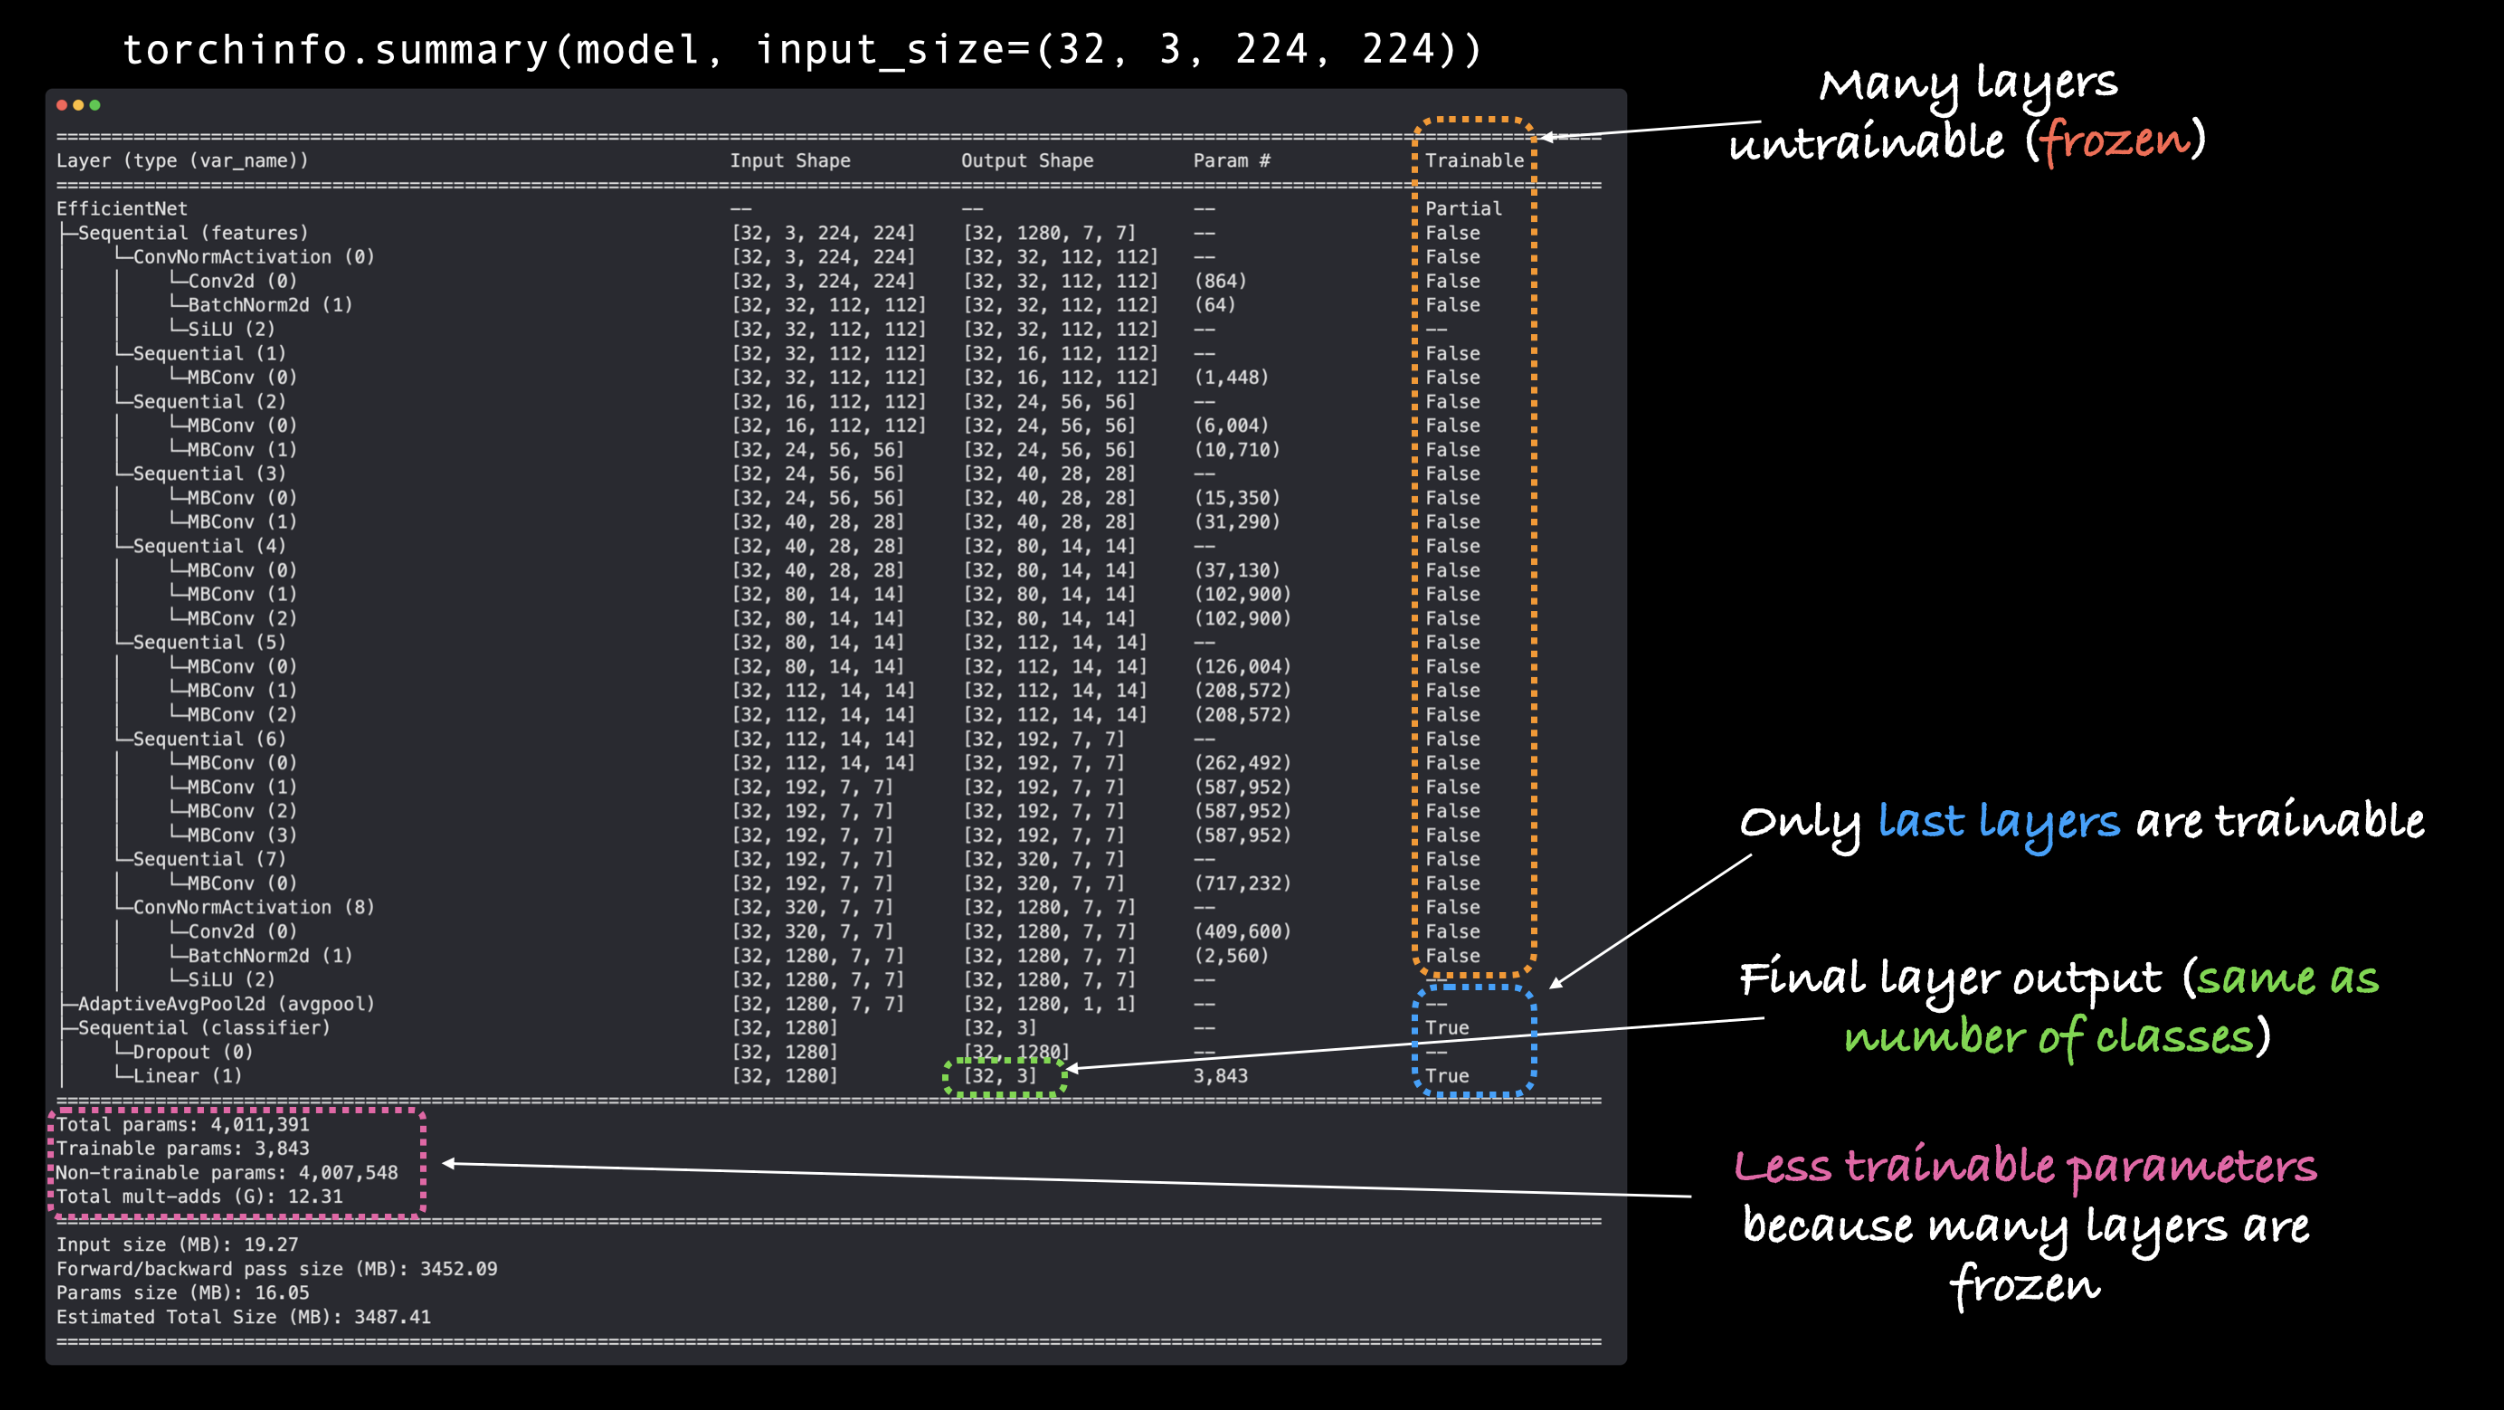

### changes

1. Trainable column - You'll see that many of the base layers (the ones in the features portion) have their Trainable value as False. This is because we set their attribute requires_grad=False. Unless we change this, these layers won't be updated during future training.

2. Output shape of classifier - The classifier portion of the model now has an Output Shape value of [32, 3] instead of [32, 1000]. It's Trainable value is also True. This means its parameters will be updated during training. In essence, we're using the features portion to feed our classifier portion a base representation of an image and then our classifier layer is going to learn how to base representation aligns with our problem.

3. Less trainable parameters - Previously there were 5,288,548 trainable parameters. But since we froze many of the layers of the model and only left the classifier as trainable, there's now only 3,843 trainable parameters (even less than our TinyVGG model). Though there's also 4,007,548 non-trainable parameters, these will create a base representation of our input images to feed into our classifier layer.

# 4. Train model

Now we've got a pretrained model that's semi-frozen and has a customised classifier

* To begin training, let's create a loss function and an optimizer.

Because we're still working with multi-class classification, we'll use nn.CrossEntropyLoss() for the loss function.

And we'll stick with torch.optim.Adam() as our optimizer with lr=0.001

In [ ]:
# define loss and optimzier
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model.parameters(),
                            lr = 0.001)


To train our model, we can use train() function we defined in the 05. PyTorch Going Modular section 04.

In [ ]:
# set the random seeds
torch.manual_seed(42)
torch.cuda.manual_seed(42)

# start the timer
from timeit import default_timer as timer
start_time = timer()

# setup training and save the results
results  = engine.train(model = model ,
                        train_dataloader = train_dataloader,
                        test_dataloader = test_dataloader,
                        optimizer = optimizer,
                        loss_fn =loss_fn,
                        epochs = 5,
                        device =device)

end_time = timer()
print(f"total training time : {end_time - start_time:.3f} seconds " )


# 5. Evaluate model by plotting loss curves

Our model looks like it's performing pretty well.

Let's plot it's loss curves to see what the training looks like over time.

We can plot the loss curves using the function plot_loss_curves() we created in 04. PyTorch Custom Datasets section 7.8.

The function is stored in the helper_functions.py script so we'll try to import it and download the script if we don't have it.

In [ ]:
# get the plot_loss_curves() function from helper_functions.py
# download the file if we dont have it

try :
  from helper_functions import plot_loss_curves
except :
  print("[info] coudln't find helper_functions.py , downloading...")
  with open("helper_functions.py" , "wb") as f:
    import requests
    request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    f.write(request.content)
  from helper_functions import plot_loss_curves

# plot the loss curves of our model
plot_loss_curves(results)


# 6. Make predictions on images from the test set

it looks like our model performs well quantitatively but how about qualitatively?

Let's find out by making some predictions with our model on images from the test set (these aren't seen during training) and plotting them.

One thing we'll have to remember is that for our model to make predictions on an image, the image has to be in same format as the images our model was trained on.

This means we'll need to make sure our images have:

* Same shape - If our images are different shapes to what our model was trained on, we'll get shape errors.

* Same datatype - If our images are a different datatype (e.g. torch.int8 vs. torch.float32) we'll get datatype errors.

* Same device - If our images are on a different device to our model, we'll get device errors.

* Same transformations - If our model is trained on images that have been transformed in certain way (e.g. normalized with a specific mean and standard deviation) and we try and make predictions on images transformed in a different way, these predictions may be off.


* To do all of this, we'll create a function pred_and_plot_image() to:

1. Take in a trained model, a list of class names, a filepath to a target image, an image size, a transform and a target device.

2. Open an image with PIL.Image.open().

3. Create a transform for the image (this will default to the manual_transforms we created above or it could use a transform generated from weights.transforms()).

4. Make sure the model is on the target device.

5. Turn on model eval mode with model.eval() (this turns off layers like nn.Dropout(), so they aren't used for inference) and the inference mode context manager.

6. Transform the target image with the transform made in step 3 and add an extra batch dimension with torch.unsqueeze(dim=0) so our input image has shape [batch_size, color_channels, height, width].

7. Make a prediction on the image by passing it to the model ensuring it's on the target device.

8. Convert the model's output logits to prediction probabilities with torch.softmax().

9. Convert model's prediction probabilities to prediction labels with torch.argmax().

10. Plot the image with matplotlib and set the title to the prediction label from step 9 and prediction probability from step 8.

In [ ]:
from typing import List , Tuple

from PIL import Image

# 1. take in a trained model , class names, image path , image size , a transform and target device
def pred_and_plot_image(model : torch.nn.Module,
                        image_path : str ,
                        class_names : List[str],
                        image_size : Tuple[int, int] = (224, 224),
                        transform :torchvision.transforms = None,
                        device : torch.device = device):
  # 2. open image
  img = Image.open(image_path)

  # 3. create transformation for image (if one doesn't exist)
  if transform is not None:
    image_transform = transform
  else :
    image_transform = transforms.Compose([
        transforms.Resize(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean = [0.485 , 0.456 ,0.406],
                             std = [0.229 , 0.224, 0.225])
    ])

    """ predict on image """

    # 4. make sure the model is on the target/right device
    model.to(device)

    # 5. turn on model evaluation mode and inference_mode
    model.eval()
    with torch.inference_mode():
      # 6. transform and add an extra dimension to image (model requires samples in batch [batch_size , color_channels , height , width ]))
      transformed_image = image_transform(img).unsqueeze(dim = 0 )

      # 7. make a prediction on image with an extra dimension and send it to the target device
      target_image_pred = model(transformed_image.to(device))

    # 8.convert logits -> prediction probabilities (using torch.softmax()) for multi-class classification
    target_image_pred_probs = torch.softmax(target_image_pred , dim = 1 )

    # 9. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 10. Plot image with predicted label and probability
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]} | Prob: {target_image_pred_probs.max():.3f}")
    plt.axis(False);


What a good looking function!

Let's test it out by making predictions on a few random images from the test set.

We can get a list of all the test image paths using list(Path(test_dir).glob("*/*.jpg")), the stars in the glob() method say "any file matching this pattern", in other words, any file ending in .jpg (all of our images).

And then we can randomly sample a number of these using Python's random.sample(population, k) where population is the sequence to sample and k is the number of samples to retrieve.

In [ ]:
# Get a random list of image paths from test set
import random
num_images_to_plot = 3
test_image_path_list = list(Path(test_dir).glob("*/*.jpg")) # get list all image paths from test data
test_image_path_sample = random.sample(population=test_image_path_list, # go through all of the test image paths
                                       k=num_images_to_plot) # randomly select 'k' image paths to pred and plot

# Make predictions on and plot the images
for image_path in test_image_path_sample:
    pred_and_plot_image(model=model,
                        image_path=image_path,
                        class_names=class_names,
                        # transform=weights.transforms(), # optionally pass in a specified transform from our pretrained model weights
                        image_size=(224, 224))

### 6.1 Making predictions on a custom image¶
It looks like our model does well qualitatively on data from the test set.

But how about on our own custom image?

That's where the real fun of machine learning is!

Predicting on your own custom data, outside of any training or test set.

To test our model on a custom image, let's import the old faithful pizza-dad.jpeg image (an image of my dad eating pizza).

We'll then pass it to the pred_and_plot_image() function we created above and see what happens.

In [ ]:
# Download custom image
import requests

# Setup custom image path
custom_image_path = data_path / "04-pizza-dad.jpeg"

# Download the image if it doesn't already exist
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

# Predict on custom image
pred_and_plot_image(model=model,
                    image_path=custom_image_path,
                    class_names=class_names)